# 05 — XAUUSD H1 Swing-Width Experiment with Per-Strategy Position Limits

## Research objective

This notebook compares four symmetric swing-pivot definitions on XAUUSD H1:

- **2-bar swing:** 2 completed candles to the left and 2 to the right of each pivot.
- **3-bar swing:** 3 candles to the left and 3 to the right.
- **4-bar swing:** 4 candles to the left and 4 to the right.
- **5-bar swing:** 5 candles to the left and 5 to the right.

For every swing width, the same EMA/ADX strategy selection is applied at setup confirmation:

1. **Bullish N** trades only when the EMA/ADX regime is **Bullish**.
2. **Ranging N** trades only when the EMA/ADX regime is **Sideways**.
3. **Bearish N is excluded** from the selected trading configuration.

### Position-capacity rules applied independently to every swing-width experiment

- Maximum **one active Bullish N position** at a time.
- Maximum **one active Ranging N position** at a time.
- Bullish N and Ranging N positions **may overlap**.
- Therefore, the combined stream can hold at most **two positions**: one per strategy.

Each swing width is a separate experiment. Position locks are independent between Bullish N and Ranging N, and results from different swing widths are not combined into one portfolio.

## Important pattern-definition note

The Bullish N rule is made explicit as a true higher-low retracement: `P1 < P3 < P2` for the pivot prices in the sequence Low → High → Low. This tightens the previous Notebook 05 implementation, which checked that P3 was above P1 but did not explicitly require P3 to remain below P2. This correction is applied consistently to all four swing widths; consequently, the new 3-bar result may differ from the earlier Notebook 05 and Notebook 04 results.

Ranging N remains the existing operational interpretation: four alternating pivots (`H-L-H-L` or `L-H-L-H`) with the two highs and two lows each within 0.50 ATR, followed by OCO breakout orders. This is not a verified reproduction of any proprietary N-Method rulebook.

> **Research status:** full-sample historical exploratory sensitivity analysis only. Comparing four swing widths on the same sample introduces model-selection bias. Do not treat the best historical width as validated or live-tradable without out-of-sample / walk-forward validation and realistic trading costs.

In [11]:
from __future__ import annotations

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view

# Works when launched from the repository root or from notebooks/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "XAUUSD_H1.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
ASSET_DIR = PROJECT_ROOT / "assets"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ASSET_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_PATH}. Keep the source CSV at data/XAUUSD_H1.csv."
    )

# Experiment dimensions: N bars on EACH side of the pivot.
SWING_WIDTHS = [2, 3, 4, 5]

# Fixed trade and indicator rules: only swing width changes within this experiment.
ATR_PERIOD = 14
RR = 2.0
ENTRY_BUFFER_ATR = 0.05
SL_BUFFER_ATR = 0.05
RANGE_TOLERANCE_ATR = 0.50
PENDING_EXPIRY_BARS = 20
EMA_FAST = 50
EMA_SLOW = 200
ADX_PERIOD = 14
ADX_THRESHOLD = 20.0
VALID_RESULTS = {"TP", "SL", "OPEN_AT_END"}

print("Project root:", PROJECT_ROOT)
print("Source data:", DATA_PATH)
print("Swing widths (bars on each side):", SWING_WIDTHS)
print("Position capacity: max 1 Bullish N + max 1 Ranging N; cross-strategy overlap allowed.")

Project root: /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern
Source data: /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/data/XAUUSD_H1.csv
Swing widths (bars on each side): [2, 3, 4, 5]
Position capacity: max 1 Bullish N + max 1 Ranging N; cross-strategy overlap allowed.


## 1. Load H1 candles and calculate the EMA/ADX regime

The CSV is headerless and interpreted as `Date, Open, High, Low, Close, Volume`. Regime classification is evaluated at the **setup-confirmation candle**. A pending stop order becomes active on the next H1 candle.

- **Bullish:** ADX(14) ≥ 20 and EMA(50) > EMA(200)
- **Bearish:** ADX(14) ≥ 20 and EMA(50) < EMA(200)
- **Sideways:** ADX(14) < 20
- **Unclassified:** required indicators are unavailable or EMA values are equal while ADX ≥ 20

In [12]:
raw = pd.read_csv(DATA_PATH, header=None)
if raw.shape[1] < 5:
    raise ValueError("Expected at least Date, Open, High, Low, and Close columns.")

column_names = ["Date", "Open", "High", "Low", "Close"]
if raw.shape[1] >= 6:
    column_names.append("Volume")
raw = raw.iloc[:, :len(column_names)].copy()
raw.columns = column_names
raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")
for col in ["Open", "High", "Low", "Close"]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")
if "Volume" in raw.columns:
    raw["Volume"] = pd.to_numeric(raw["Volume"], errors="coerce")

data = (
    raw.dropna(subset=["Date", "Open", "High", "Low", "Close"])
       .sort_values("Date")
       .drop_duplicates("Date")
       .set_index("Date")
)

invalid = (data["High"] < data[["Open", "Close", "Low"]].max(axis=1)) | (
    data["Low"] > data[["Open", "Close", "High"]].min(axis=1)
)
if invalid.any():
    raise ValueError(f"Found {int(invalid.sum())} invalid OHLC rows.")

# ATR: simple rolling mean of True Range, consistent with the existing H1 notebooks.
prev_close = data["Close"].shift(1)
true_range = pd.concat([
    data["High"] - data["Low"],
    (data["High"] - prev_close).abs(),
    (data["Low"] - prev_close).abs(),
], axis=1).max(axis=1)
data["ATR"] = true_range.rolling(ATR_PERIOD, min_periods=ATR_PERIOD).mean()

# EMA(50) / EMA(200)
data["EMA50"] = data["Close"].ewm(span=EMA_FAST, adjust=False, min_periods=EMA_FAST).mean()
data["EMA200"] = data["Close"].ewm(span=EMA_SLOW, adjust=False, min_periods=EMA_SLOW).mean()

# Wilder-style ADX(14), same formula as the baseline notebooks.
up_move = data["High"].diff()
down_move = -data["Low"].diff()
plus_dm = pd.Series(np.where((up_move > down_move) & (up_move > 0), up_move, 0.0), index=data.index)
minus_dm = pd.Series(np.where((down_move > up_move) & (down_move > 0), down_move, 0.0), index=data.index)
smoothed_tr = true_range.ewm(alpha=1 / ADX_PERIOD, adjust=False, min_periods=ADX_PERIOD).mean()
smoothed_plus_dm = plus_dm.ewm(alpha=1 / ADX_PERIOD, adjust=False, min_periods=ADX_PERIOD).mean()
smoothed_minus_dm = minus_dm.ewm(alpha=1 / ADX_PERIOD, adjust=False, min_periods=ADX_PERIOD).mean()
data["+DI14"] = 100 * smoothed_plus_dm / smoothed_tr
data["-DI14"] = 100 * smoothed_minus_dm / smoothed_tr
dx = 100 * (data["+DI14"] - data["-DI14"]).abs() / (data["+DI14"] + data["-DI14"])
data["ADX14"] = dx.ewm(alpha=1 / ADX_PERIOD, adjust=False, min_periods=ADX_PERIOD).mean()

conditions = [
    data["ADX14"] < ADX_THRESHOLD,
    (data["ADX14"] >= ADX_THRESHOLD) & (data["EMA50"] > data["EMA200"]),
    (data["ADX14"] >= ADX_THRESHOLD) & (data["EMA50"] < data["EMA200"]),
]
data["Regime"] = np.select(conditions, ["Sideways", "Bullish", "Bearish"], default="Unclassified")

print(f"H1 bars: {len(data):,}")
print(f"Date range: {data.index.min()} to {data.index.max()}")
print("Duplicate timestamps removed:", int(raw["Date"].duplicated().sum()))
display(data[["Open", "High", "Low", "Close", "ATR", "EMA50", "EMA200", "ADX14", "Regime"]].tail())
display(data["Regime"].value_counts().rename_axis("Regime").to_frame("Bars"))

H1 bars: 100,000
Date range: 2010-02-22 18:00:00 to 2026-11-12 06:00:00
Duplicate timestamps removed: 0


,Open,High,Low,Close,ATR,EMA50,EMA200,ADX14,Regime
Date,,,,,,,,,
2026-11-12 02:00:00,3985.415,3989.760,3973.685,3980.377,14.192857,4036.380630,4046.640681,36.092844,Bearish
2026-11-12 03:00:00,3980.375,3984.860,3976.535,3982.608,14.298929,4034.271899,4046.003539,36.622316,Bearish
2026-11-12 04:00:00,3982.608,3983.317,3972.595,3975.208,14.018357,4031.955668,4045.299106,37.332925,Bearish
2026-11-12 05:00:00,3975.208,3982.911,3969.525,3979.407,13.008429,4029.894936,4044.643463,38.158972,Bearish
2026-11-12 06:00:00,3979.407,3980.750,3962.245,3965.600,13.050429,4027.373566,4043.856961,39.291329,Bearish


,Bars
Regime,
Bullish,37711
Bearish,31640
Sideways,30461
Unclassified,188


## 2. Confirm swing pivots without look-ahead

For a swing width `N`, the candidate pivot is the center candle of a `2N + 1` candle window. A pivot is only usable at its **confirmation candle**, `N` H1 bars after the candidate pivot candle. The center must be the local extreme; an equal extreme to its right disqualifies it (same tie-handling convention as the earlier notebooks).

| Swing width | Total candles in pivot window | Confirmation delay |
|---:|---:|---:|
| 2 | 5 | 2 H1 bars |
| 3 | 7 | 3 H1 bars |
| 4 | 9 | 4 H1 bars |
| 5 | 11 | 5 H1 bars |

In [13]:
def confirmed_pivots(frame: pd.DataFrame, left: int, right: int) -> list[dict]:
    """Detect local high/low pivots and timestamp them only when confirmed."""
    highs = frame["High"].to_numpy(dtype=float)
    lows = frame["Low"].to_numpy(dtype=float)
    width = left + right + 1
    if len(frame) < width:
        return []

    high_windows = sliding_window_view(highs, width)
    low_windows = sliding_window_view(lows, width)
    center_high = high_windows[:, left]
    center_low = low_windows[:, left]

    is_high = (center_high >= high_windows.max(axis=1)) & ~(
        high_windows[:, left + 1:] == center_high[:, None]
    ).any(axis=1)
    is_low = (center_low <= low_windows.min(axis=1)) & ~(
        low_windows[:, left + 1:] == center_low[:, None]
    ).any(axis=1)

    points = []
    for offset in np.flatnonzero(is_high | is_low):
        pivot_i = int(offset + left)
        confirm_i = pivot_i + right
        if is_high[offset]:
            points.append({
                "type": "H", "pivot_i": pivot_i, "confirm_i": confirm_i,
                "price": float(highs[pivot_i]), "date": frame.index[pivot_i],
            })
        if is_low[offset]:
            points.append({
                "type": "L", "pivot_i": pivot_i, "confirm_i": confirm_i,
                "price": float(lows[pivot_i]), "date": frame.index[pivot_i],
            })
    points.sort(key=lambda p: (p["confirm_i"], p["pivot_i"], p["type"]))
    return points

## 3. Build Bullish N and Ranging N candidates for each swing width

The strategy structures and all trade-management parameters remain identical across swing widths.

### Bullish N

- Three confirmed pivots in sequence: `Low → High → Low`.
- The second low must be a higher low but remain below the intervening high: **`P1 < P3 < P2`**.
- Buy stop: `P2 + 0.05 × ATR(14)`.
- Stop-loss: `P3 − 0.05 × ATR(14)`.

### Ranging N

- Four confirmed alternating pivots: `H-L-H-L` or `L-H-L-H`.
- Difference between the two highs ≤ `0.50 × ATR(14)`.
- Difference between the two lows ≤ `0.50 × ATR(14)`.
- Place OCO buy-stop / sell-stop orders beyond the range boundaries, each with a `0.05 × ATR(14)` buffer and a stop beyond the opposite boundary.

Bearish N is excluded. Setup eligibility is determined using the EMA/ADX regime at the final pivot's confirmation candle: Bullish N → Bullish; Ranging N → Sideways.

In [14]:
def build_selected_setups(frame: pd.DataFrame, pivot_points: list[dict]) -> dict[str, list[dict]]:
    atr = frame["ATR"].to_numpy(dtype=float)
    candidates = {"bullish": [], "ranging": []}

    # Bullish N: Low -> High -> Higher Low, explicitly P1 < P3 < P2.
    for k in range(2, len(pivot_points)):
        p1, p2, p3 = pivot_points[k - 2:k + 1]
        if [p1["type"], p2["type"], p3["type"]] != ["L", "H", "L"]:
            continue
        if not (p1["price"] < p3["price"] < p2["price"]):
            continue
        signal_i = int(p3["confirm_i"])
        a = atr[signal_i]
        if not np.isfinite(a) or a <= 0:
            continue
        entry = p2["price"] + ENTRY_BUFFER_ATR * a
        sl = p3["price"] - SL_BUFFER_ATR * a
        if sl < entry:
            candidates["bullish"].append({
                "signal_i": signal_i,
                "setup_type": "bullish",
                "orders": [{"side": "long", "entry": entry, "sl": sl}],
                "pattern": f"P1={p1['price']:.2f}; P2={p2['price']:.2f}; P3={p3['price']:.2f}",
            })

    # Ranging N: two similar highs and two similar lows over four alternating pivots.
    for k in range(3, len(pivot_points)):
        q = pivot_points[k - 3:k + 1]
        types = [point["type"] for point in q]
        if types not in (["H", "L", "H", "L"], ["L", "H", "L", "H"]):
            continue
        highs = [point["price"] for point in q if point["type"] == "H"]
        lows = [point["price"] for point in q if point["type"] == "L"]
        signal_i = int(q[-1]["confirm_i"])
        a = atr[signal_i]
        if not np.isfinite(a) or a <= 0:
            continue
        range_high, range_low = max(highs), min(lows)
        high_ok = abs(highs[1] - highs[0]) <= RANGE_TOLERANCE_ATR * a
        low_ok = abs(lows[1] - lows[0]) <= RANGE_TOLERANCE_ATR * a
        if high_ok and low_ok and range_high > range_low:
            candidates["ranging"].append({
                "signal_i": signal_i,
                "setup_type": "ranging",
                "orders": [
                    {"side": "long", "entry": range_high + ENTRY_BUFFER_ATR * a,
                     "sl": range_low - SL_BUFFER_ATR * a},
                    {"side": "short", "entry": range_low - ENTRY_BUFFER_ATR * a,
                     "sl": range_high + SL_BUFFER_ATR * a},
                ],
                "pattern": f"RangeLow={range_low:.2f}; RangeHigh={range_high:.2f}",
            })
    return candidates

## 4. Backtest engine: one position slot per strategy

Regime eligibility is applied **before** the setup stream enters the position-capacity backtest. The Bullish N and Ranging N streams are then simulated independently, each with its own position lock. This enforces at most one open position per strategy while allowing a Bullish N position and a Ranging N position to overlap.

Execution assumptions:

- Signal is known only after the pivot-confirmation candle closes.
- Pending orders become active on the following H1 candle.
- Pending orders expire after 20 active H1 candles.
- Entry and exit fills are gap-aware using the candle open when it gaps through a stop level.
- Fixed take-profit is 2R.
- If SL and TP are both touched in the same candle, SL is assumed first.
- If both sides of a Ranging N OCO trigger in the same candle, the setup is marked ambiguous and excluded from valid performance statistics.
- An open trade at the final data candle is marked to the final close (`OPEN_AT_END`); it is not a realized closed trade.

In [15]:
def backtest_one_strategy(frame: pd.DataFrame, setup_list: list[dict]) -> pd.DataFrame:
    """Sequential single-position backtest; call separately for each strategy."""
    n = len(frame)
    idx = frame.index
    open_ = frame["Open"].to_numpy(dtype=float)
    high = frame["High"].to_numpy(dtype=float)
    low = frame["Low"].to_numpy(dtype=float)
    close = frame["Close"].to_numpy(dtype=float)
    regime_arr = frame["Regime"].to_numpy()
    results = []
    busy_until = -1

    for setup in sorted(setup_list, key=lambda item: item["signal_i"]):
        signal_i = int(setup["signal_i"])
        if signal_i + 1 >= n:
            continue
        # One slot per strategy. Signals through the exit candle are skipped.
        if signal_i <= busy_until:
            continue

        first_active = signal_i + 1
        last_active = min(n - 1, first_active + PENDING_EXPIRY_BARS - 1)
        valid_order_hits = []

        for order in setup["orders"]:
            side = order["side"]
            entry_level = float(order["entry"])
            stop_level = float(order["sl"])
            touched = (high[first_active:last_active + 1] >= entry_level) if side == "long" else (
                low[first_active:last_active + 1] <= entry_level
            )
            for offset in np.flatnonzero(touched):
                entry_i = first_active + int(offset)
                fill = max(entry_level, float(open_[entry_i])) if side == "long" else min(
                    entry_level, float(open_[entry_i])
                )
                if (side == "long" and stop_level >= fill) or (side == "short" and stop_level <= fill):
                    continue
                risk = abs(fill - stop_level)
                target = fill + RR * risk if side == "long" else fill - RR * risk
                valid_order_hits.append({
                    "i": entry_i, "side": side, "entry": fill,
                    "sl": stop_level, "tp": target, "risk": risk,
                })
                break

        if not valid_order_hits:
            continue

        earliest_i = min(hit["i"] for hit in valid_order_hits)
        hits_at_earliest = [hit for hit in valid_order_hits if hit["i"] == earliest_i]
        if len(hits_at_earliest) > 1:
            results.append({
                "setup": setup["setup_type"], "side": "ambiguous",
                "signal_date": idx[signal_i], "entry_date": idx[earliest_i],
                "entry": np.nan, "sl": np.nan, "tp": np.nan,
                "exit_date": idx[earliest_i], "exit": np.nan,
                "result": "AMBIGUOUS_BOTH_SIDES", "R": 0.0, "bars_held": 0,
                "pattern": setup.get("pattern", ""), "signal_regime": regime_arr[signal_i],
            })
            busy_until = earliest_i
            continue

        hit = hits_at_earliest[0]
        side, entry, stop_level, target, risk = (
            hit["side"], hit["entry"], hit["sl"], hit["tp"], hit["risk"]
        )
        start = earliest_i
        stop_hits = (low[start:] <= stop_level) if side == "long" else (high[start:] >= stop_level)
        target_hits = (high[start:] >= target) if side == "long" else (low[start:] <= target)
        exit_offsets = np.flatnonzero(stop_hits | target_hits)

        if len(exit_offsets):
            offset = int(exit_offsets[0])
            exit_i = start + offset
            if stop_hits[offset]:
                if side == "long":
                    exit_price = min(stop_level, float(open_[exit_i])) if open_[exit_i] < stop_level else stop_level
                else:
                    exit_price = max(stop_level, float(open_[exit_i])) if open_[exit_i] > stop_level else stop_level
                result = "SL"
            else:
                if side == "long":
                    exit_price = max(target, float(open_[exit_i])) if open_[exit_i] > target else target
                else:
                    exit_price = min(target, float(open_[exit_i])) if open_[exit_i] < target else target
                result = "TP"
        else:
            exit_i = n - 1
            exit_price = float(close[-1])
            result = "OPEN_AT_END"

        pnl_points = exit_price - entry if side == "long" else entry - exit_price
        r_multiple = pnl_points / risk if risk > 0 else np.nan
        results.append({
            "setup": setup["setup_type"], "side": side,
            "signal_date": idx[signal_i], "entry_date": idx[start],
            "entry": entry, "sl": stop_level, "tp": target,
            "exit_date": idx[exit_i], "exit": exit_price,
            "result": result, "R": r_multiple, "bars_held": exit_i - start + 1,
            "pattern": setup.get("pattern", ""), "signal_regime": regime_arr[signal_i],
        })
        busy_until = exit_i

    return pd.DataFrame(results)


def summarize_performance(frame: pd.DataFrame) -> dict:
    valid = frame[frame["result"].isin(VALID_RESULTS)].copy() if not frame.empty else pd.DataFrame()
    ambiguous = int((frame["result"] == "AMBIGUOUS_BOTH_SIDES").sum()) if not frame.empty else 0
    if valid.empty:
        return {
            "Trades": 0, "Win rate %": np.nan, "Net R": 0.0,
            "Profit factor": np.nan, "Avg R": np.nan,
            "Max drawdown R": 0.0, "Ambiguous OCO": ambiguous,
        }
    valid = valid.sort_values(["exit_date", "signal_date"])
    gross_profit = valid.loc[valid["R"] > 0, "R"].sum()
    gross_loss = -valid.loc[valid["R"] < 0, "R"].sum()
    increments = valid.groupby("exit_date")["R"].sum().sort_index()
    equity = increments.cumsum()
    drawdown = equity - equity.cummax().clip(lower=0)
    return {
        "Trades": len(valid),
        "Win rate %": 100 * (valid["R"] > 0).mean(),
        "Net R": valid["R"].sum(),
        "Profit factor": gross_profit / gross_loss if gross_loss > 0 else np.inf,
        "Avg R": valid["R"].mean(),
        "Max drawdown R": drawdown.min(),
        "Ambiguous OCO": ambiguous,
    }


def cumulative_r_curve(frame: pd.DataFrame, start_time: pd.Timestamp) -> pd.Series:
    valid = frame[frame["result"].isin(VALID_RESULTS)].copy() if not frame.empty else pd.DataFrame()
    if valid.empty:
        return pd.Series(dtype=float)
    increments = valid.groupby("exit_date")["R"].sum().sort_index()
    start_time = pd.Timestamp(start_time)
    increments.loc[start_time] = increments.get(start_time, 0.0)
    return increments.groupby(level=0).sum().sort_index().cumsum()

## 5. Run the four swing-width experiments

For each width, the notebook:

1. Detects pivots using `N` candles on both sides.
2. Generates Bullish N and Ranging N candidates.
3. Applies EMA/ADX eligibility at each setup's confirmation time **before** running the position-capacity backtest.
4. Runs Bullish N and Ranging N separately, each with one position slot.
5. Combines the two streams only for reporting and concurrency auditing; one Bullish and one Ranging position may overlap.

In [16]:
all_selected_trade_frames = []
setup_count_rows = []
performance_rows = []
capacity_rows = []
selected_frames_by_width = {}
strategy_frames_by_width = {}
pivot_counts = {}

regime_values = data["Regime"].to_numpy()

for swing_bars in SWING_WIDTHS:
    pivots = confirmed_pivots(data, left=swing_bars, right=swing_bars)
    candidates = build_selected_setups(data, pivots)
    pivot_counts[swing_bars] = len(pivots)

    eligible = {
        "bullish": [s for s in candidates["bullish"]
                    if regime_values[int(s["signal_i"])] == "Bullish"],
        "ranging": [s for s in candidates["ranging"]
                    if regime_values[int(s["signal_i"])] == "Sideways"],
    }

    # Each strategy gets its own independent one-position lock.
    by_strategy = {
        strategy: backtest_one_strategy(data, setup_list)
        for strategy, setup_list in eligible.items()
    }
    combined_parts = [df for df in by_strategy.values() if not df.empty]
    combined = pd.concat(combined_parts, ignore_index=True) if combined_parts else pd.DataFrame()
    if not combined.empty:
        combined["swing_bars_each_side"] = swing_bars
        combined["pivot_window_bars"] = 2 * swing_bars + 1
        combined = combined.sort_values(["entry_date", "setup", "signal_date"]).reset_index(drop=True)
        all_selected_trade_frames.append(combined)

    selected_frames_by_width[swing_bars] = combined
    strategy_frames_by_width[swing_bars] = by_strategy

    setup_count_rows.append({
        "Swing bars each side": swing_bars,
        "Pivot window bars": 2 * swing_bars + 1,
        "Confirmed pivots": len(pivots),
        "Bullish N candidates": len(candidates["bullish"]),
        "Bullish N eligible in Bullish regime": len(eligible["bullish"]),
        "Ranging N candidates": len(candidates["ranging"]),
        "Ranging N eligible in Sideways regime": len(eligible["ranging"]),
    })

    for key, label in [
        ("bullish", "Bullish N + EMA/ADX Bullish"),
        ("ranging", "Ranging N + EMA/ADX Sideways"),
        ("combined", "Combined — one position per strategy"),
    ]:
        frame = combined if key == "combined" else by_strategy[key]
        performance_rows.append({
            "Swing bars each side": swing_bars,
            "Pivot window bars": 2 * swing_bars + 1,
            "Selection": label,
            **summarize_performance(frame),
        })

print("Candidate and regime-eligible setup counts")
setup_counts = pd.DataFrame(setup_count_rows)
display(setup_counts)

print("Performance by swing width and strategy")
performance_summary = pd.DataFrame(performance_rows)
display(performance_summary.round(3))

all_selected_trades = (
    pd.concat(all_selected_trade_frames, ignore_index=True)
    if all_selected_trade_frames else pd.DataFrame()
)

Candidate and regime-eligible setup counts


,Swing bars each side,Pivot window bars,Confirmed pivots,Bullish N candidates,Bullish N eligible in Bullish regime,Ranging N candidates,Ranging N eligible in Sideways regime
0,2,5,27648,4375,1589,1244,506
1,3,7,19846,3131,1133,622,277
2,4,9,15396,2420,811,349,180
3,5,11,12501,2031,703,223,123


Performance by swing width and strategy


,Swing bars each side,Pivot window bars,Selection,Trades,Win rate %,Net R,Profit factor,Avg R,Max drawdown R,Ambiguous OCO
0,2,5,Bullish N + EMA/ADX Bullish,766,35.770,50.098,1.101,0.065,-28.015,0
1,2,5,Ranging N + EMA/ADX Sideways,322,41.304,77.248,1.405,0.240,-9.000,9
2,2,5,Combined — one position per strategy,1088,37.408,127.346,1.185,0.117,-33.015,9
3,3,7,Bullish N + EMA/ADX Bullish,564,35.816,39.962,1.109,0.071,-27.254,0
4,3,7,Ranging N + EMA/ADX Sideways,194,41.753,48.818,1.431,0.252,-12.182,3
5,3,7,Combined — one position per strategy,758,37.335,88.780,1.185,0.117,-25.431,3
6,4,9,Bullish N + EMA/ADX Bullish,410,34.390,11.497,1.042,0.028,-25.455,0
7,4,9,Ranging N + EMA/ADX Sideways,134,33.582,1.582,1.018,0.012,-22.000,3
8,4,9,Combined — one position per strategy,544,34.191,13.079,1.036,0.024,-35.455,3
9,5,11,Bullish N + EMA/ADX Bullish,333,39.039,55.976,1.274,0.168,-22.006,0


## 6. Verify per-strategy position capacity for every swing width

An open position is counted from its entry candle through its exit candle, inclusive. Ambiguous OCO signals are not positions and are excluded from this audit. The audit checks that, for **each swing width**, the maximum Bullish N concurrency is 1, maximum Ranging N concurrency is 1, and maximum combined concurrency is no more than 2.

In [17]:
def concurrency_audit(frame: pd.DataFrame, swing_bars: int) -> tuple[dict, pd.DataFrame]:
    n = len(data)
    index_to_i = {timestamp: i for i, timestamp in enumerate(data.index)}
    delta_all = np.zeros(n + 1, dtype=int)
    deltas = {"bullish": np.zeros(n + 1, dtype=int), "ranging": np.zeros(n + 1, dtype=int)}
    valid = frame[frame["result"].isin(VALID_RESULTS)].copy() if not frame.empty else pd.DataFrame()
    for _, trade in valid.iterrows():
        start_i = index_to_i[trade["entry_date"]]
        end_i = index_to_i[trade["exit_date"]]
        delta_all[start_i] += 1
        delta_all[end_i + 1] -= 1
        deltas[trade["setup"]][start_i] += 1
        deltas[trade["setup"]][end_i + 1] -= 1

    total_active = np.cumsum(delta_all[:-1])
    active = {name: np.cumsum(delta[:-1]) for name, delta in deltas.items()}
    max_bull = int(active["bullish"].max()) if len(active["bullish"]) else 0
    max_range = int(active["ranging"].max()) if len(active["ranging"]) else 0
    max_total = int(total_active.max()) if len(total_active) else 0

    bull = valid[valid["setup"] == "bullish"]
    rang = valid[valid["setup"] == "ranging"]
    overlap_pairs = 0
    for _, b in bull.iterrows():
        overlap_pairs += int(((rang["entry_date"] <= b["exit_date"]) &
                              (rang["exit_date"] >= b["entry_date"])).sum())

    row = {
        "Swing bars each side": swing_bars,
        "Max concurrent Bullish N": max_bull,
        "Max concurrent Ranging N": max_range,
        "Max combined positions": max_total,
        "H1 bars with both strategies open": int((total_active == 2).sum()),
        "Overlapping Bullish/Ranging trade pairs": overlap_pairs,
        "Bullish cap passed": max_bull <= 1,
        "Ranging cap passed": max_range <= 1,
        "Combined cap passed": max_total <= 2,
    }
    ts = pd.DataFrame({
        "Timestamp": data.index,
        "Bullish N open positions": active["bullish"],
        "Ranging N open positions": active["ranging"],
        "Total open positions": total_active,
        "Swing bars each side": swing_bars,
    })
    return row, ts

concurrency_frames = []
for swing_bars in SWING_WIDTHS:
    audit_row, ts = concurrency_audit(selected_frames_by_width[swing_bars], swing_bars)
    capacity_rows.append(audit_row)
    concurrency_frames.append(ts)

capacity_audit = pd.DataFrame(capacity_rows)
display(capacity_audit)

assert capacity_audit["Bullish cap passed"].all(), "Bullish N position cap violated."
assert capacity_audit["Ranging cap passed"].all(), "Ranging N position cap violated."
assert capacity_audit["Combined cap passed"].all(), "Combined two-position cap violated."
print("PASS: all four swing-width experiments satisfy max 1 Bullish N + max 1 Ranging N, with cross-strategy overlap allowed.")

,Swing bars each side,Max concurrent Bullish N,Max concurrent Ranging N,Max combined positions,H1 bars with both strategies open,Overlapping Bullish/Ranging trade pairs,Bullish cap passed,Ranging cap passed,Combined cap passed
0,2,1,1,2,1098,100,True,True,True
1,3,1,1,2,777,69,True,True,True
2,4,1,1,2,798,43,True,True,True
3,5,1,1,2,355,18,True,True,True


PASS: all four swing-width experiments satisfy max 1 Bullish N + max 1 Ranging N, with cross-strategy overlap allowed.


## 7. Compare cumulative Net R across swing widths

Cumulative performance is grouped by trade exit timestamp. `OPEN_AT_END` trades are included as final mark-to-market observations, not realized closed trades. The combined series aggregates the two strategy streams in R units; it is not a shared-capital account simulation.

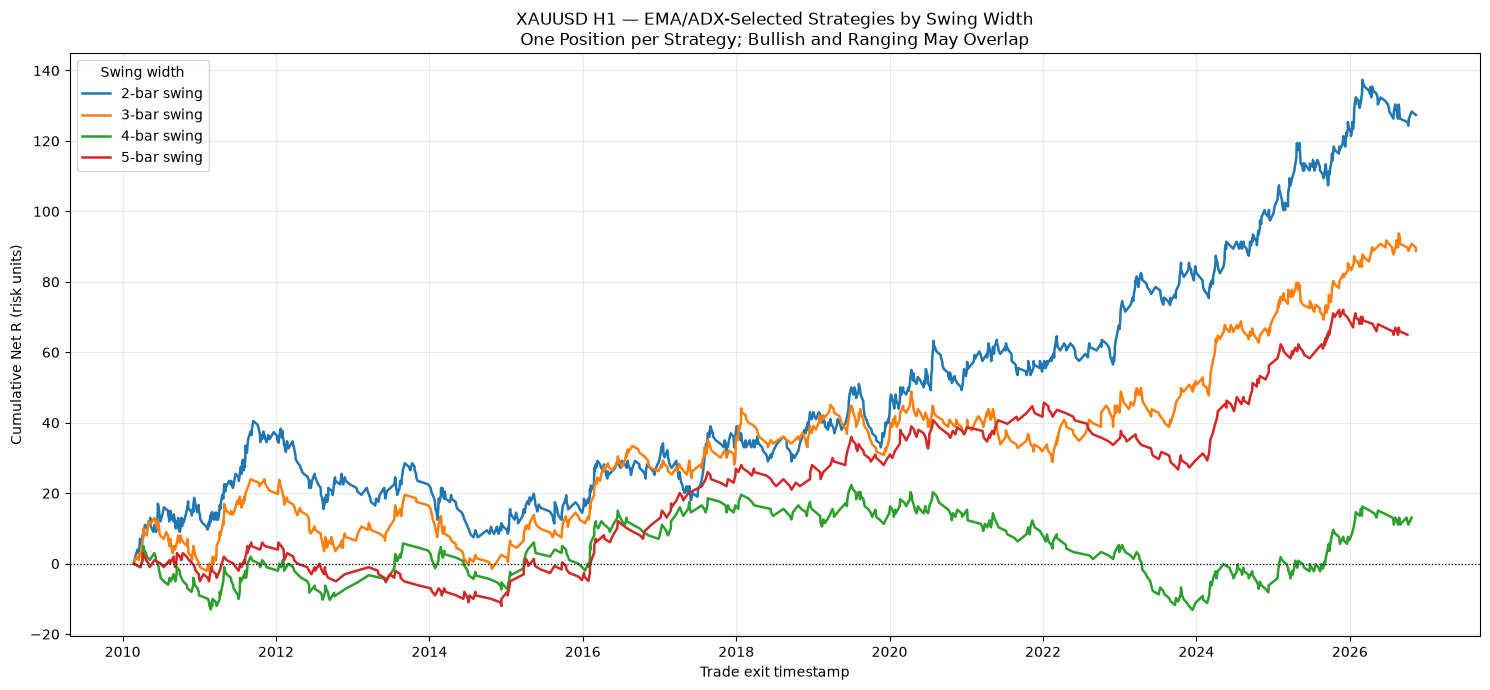

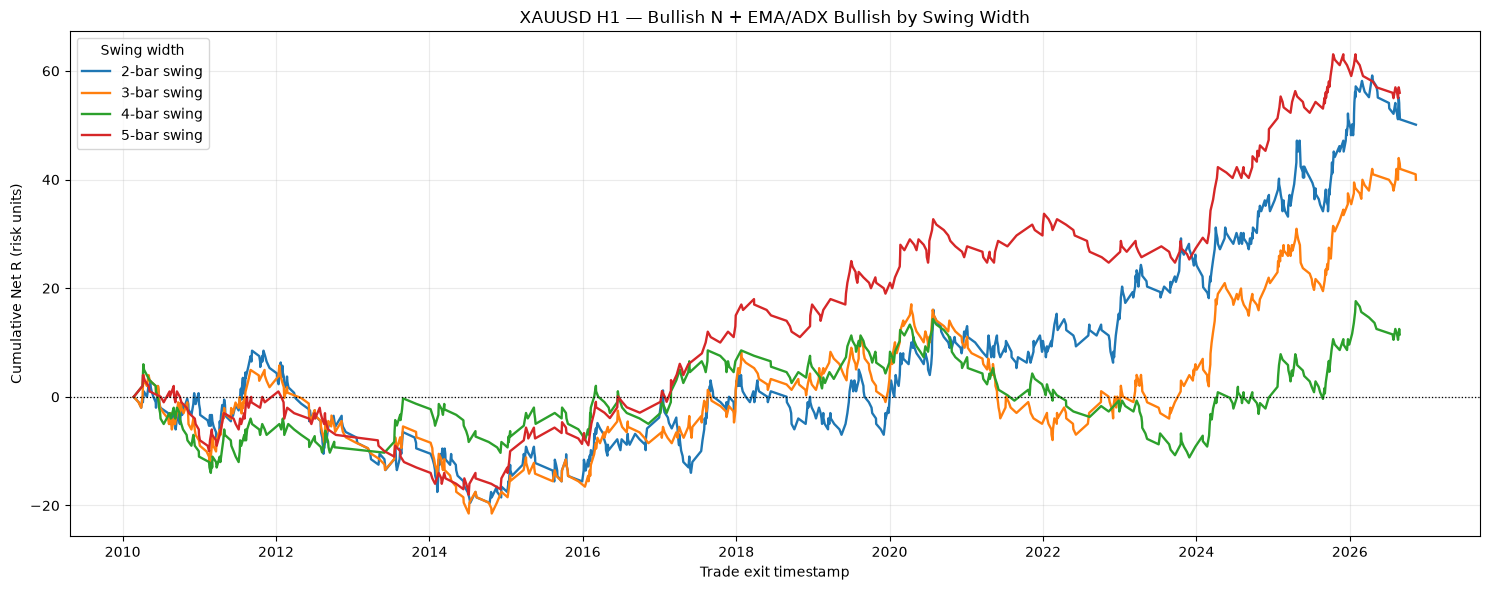

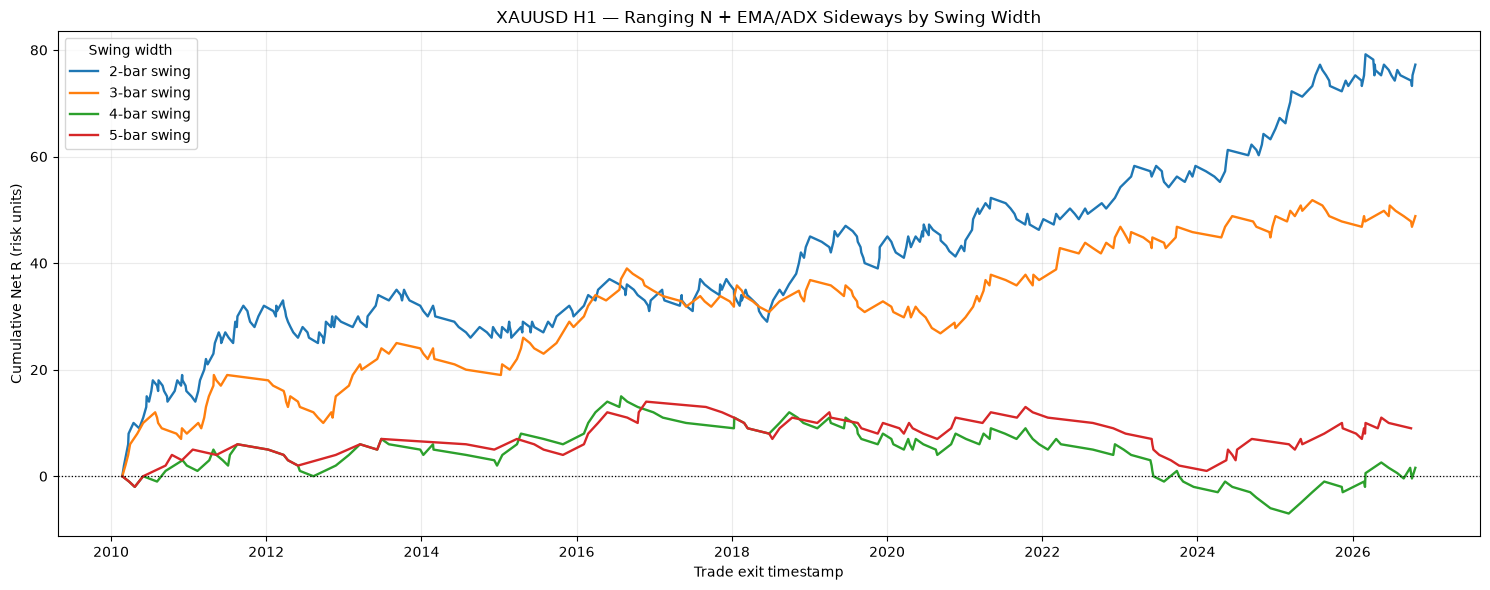

Saved chart: /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/assets/h1_swing_width_position_capped_combined_cumulative_R.png


In [18]:
plt.figure(figsize=(15, 7))
curve_rows = []
for swing_bars in SWING_WIDTHS:
    frame = selected_frames_by_width[swing_bars]
    curve = cumulative_r_curve(frame, data.index.min())
    if not curve.empty:
        plt.plot(curve.index, curve.values, linewidth=1.8, label=f"{swing_bars}-bar swing")
        for timestamp, value in curve.items():
            curve_rows.append({
                "exit_date": timestamp,
                "Swing bars each side": swing_bars,
                "Cumulative Net R": value,
            })
plt.axhline(0, color="black", linewidth=0.9, linestyle=":")
plt.title("XAUUSD H1 — EMA/ADX-Selected Strategies by Swing Width\nOne Position per Strategy; Bullish and Ranging May Overlap")
plt.xlabel("Trade exit timestamp")
plt.ylabel("Cumulative Net R (risk units)")
plt.grid(True, alpha=0.25)
plt.legend(title="Swing width")
plt.tight_layout()
combined_chart_path = ASSET_DIR / "h1_swing_width_position_capped_combined_cumulative_R.png"
plt.savefig(combined_chart_path, dpi=160, bbox_inches="tight")
plt.show()

# Component-level comparison: each strategy has one independent position slot.
for setup_name, title, filename in [
    ("bullish", "Bullish N + EMA/ADX Bullish", "h1_swing_width_position_capped_bullish_cumulative_R.png"),
    ("ranging", "Ranging N + EMA/ADX Sideways", "h1_swing_width_position_capped_ranging_cumulative_R.png"),
]:
    plt.figure(figsize=(15, 6))
    for swing_bars in SWING_WIDTHS:
        frame = strategy_frames_by_width[swing_bars][setup_name]
        curve = cumulative_r_curve(frame, data.index.min())
        if not curve.empty:
            plt.plot(curve.index, curve.values, linewidth=1.7, label=f"{swing_bars}-bar swing")
    plt.axhline(0, color="black", linewidth=0.9, linestyle=":")
    plt.title(f"XAUUSD H1 — {title} by Swing Width")
    plt.xlabel("Trade exit timestamp")
    plt.ylabel("Cumulative Net R (risk units)")
    plt.grid(True, alpha=0.25)
    plt.legend(title="Swing width")
    plt.tight_layout()
    plt.savefig(ASSET_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

cumulative_curves = pd.DataFrame(curve_rows)
print("Saved chart:", combined_chart_path)

## 8. Compare component contributions and drawdown

The combined result can conceal differences between Bullish N and Ranging N. Review component performance, drawdown, sample size, and capacity audit together rather than selecting a swing width by Net R alone.

In [19]:
combined_summary = performance_summary[
    performance_summary["Selection"].eq("Combined — one position per strategy")
].sort_values("Swing bars each side").reset_index(drop=True)
component_summary = performance_summary[
    performance_summary["Selection"].isin([
        "Bullish N + EMA/ADX Bullish", "Ranging N + EMA/ADX Sideways"
    ])
]

print("Combined result by swing width")
display(combined_summary[[
    "Swing bars each side", "Pivot window bars", "Trades", "Win rate %",
    "Net R", "Profit factor", "Avg R", "Max drawdown R", "Ambiguous OCO"
]].round(3))

print("Component contribution")
component_pivot = component_summary.pivot(
    index="Swing bars each side", columns="Selection", values="Net R"
)
display(component_pivot.round(3))

Combined result by swing width


,Swing bars each side,Pivot window bars,Trades,Win rate %,Net R,Profit factor,Avg R,Max drawdown R,Ambiguous OCO
0,2,5,1088,37.408,127.346,1.185,0.117,-33.015,9
1,3,7,758,37.335,88.780,1.185,0.117,-25.431,3
2,4,9,544,34.191,13.079,1.036,0.024,-35.455,3
3,5,11,426,38.498,64.976,1.247,0.153,-19.000,3


Component contribution


Selection,Bullish N + EMA/ADX Bullish,Ranging N + EMA/ADX Sideways
Swing bars each side,,
2,50.098,77.248
3,39.962,48.818
4,11.497,1.582
5,55.976,9.000


## 10. Fixed-lot account simulation: USD 1,000 starting balance, 0.01 lot

This section converts the backtest's entry/exit price differences into a simplified USD account simulation for each swing width.

### Configurable account assumptions

- Starting balance: **USD 1,000**.
- Fixed order size: **0.01 lot per position**.
- Assumed XAUUSD contract size: **100 troy ounces per 1.00 lot**; therefore 0.01 lot represents 1 troy ounce.
- Under this assumption, a USD 1.00 move in XAUUSD produces approximately USD 1.00 P/L for a 0.01-lot position.
- Both strategies may be open simultaneously, so each can hold its own 0.01-lot position.

**Broker specification warning:** Contract size, account currency conversion, tick value, and minimum lot rules vary by broker and account type. Verify the XAUUSD contract specification before relying on these figures. This is a price-difference approximation, not a broker-exact margin or execution simulator.

### Calculation and reporting conventions

- Trade P/L = `(exit price − entry price) × direction × lot size × contract size`.
- Trades are ordered by exit timestamp, then entry timestamp and strategy for a reproducible consecutive-loss count. If multiple positions close at the same timestamp, this ordering is a convention; their P/L is also aggregated by timestamp for the account equity curve.
- Maximum consecutive losses are reported for the combined stream and separately for Bullish N and Ranging N.
- Maximum drawdown is calculated from the realized/marked-to-market exit-event equity curve, starting from USD 1,000.
- `OPEN_AT_END`, if present, is a final mark-to-market observation, not a realized closed trade.
- No spread, commission, swap, slippage, margin, stop-out, or financing costs are included. Fixed lot size means the percentage risk per trade changes as the stop distance changes.


Assumptions: starting balance=$1,000.00; lot=0.01; contract=100 oz/lot; P/L multiplier=$1.00 per $1.00 XAUUSD move.
Combined account simulation by swing width


,Swing bars each side,Trades,Net P/L USD,Ending equity USD,Max consecutive losses,Max drawdown USD,Worst single-trade loss USD
0,2,1088,1757.94,2757.94,18,-681.10,-142.90
3,3,758,1401.98,2401.98,13,-328.04,-104.30
6,4,544,546.63,1546.63,12,-557.96,-104.29
9,5,426,908.74,1908.74,10,-579.12,-143.27


Strategy-level account simulation


,Swing bars each side,Selection,Starting balance USD,Lot size per position,Trades,Net P/L USD,Ending equity USD,Max consecutive losses,Max drawdown USD,Worst single-trade loss USD
0,2,Combined — Bullish N + Ranging N,1000.0,0.01,1088,1757.94,2757.94,18,-681.10,-142.90
1,2,Bullish N,1000.0,0.01,766,900.45,1900.45,12,-374.78,-73.09
2,2,Ranging N,1000.0,0.01,322,857.49,1857.49,8,-333.98,-142.90
3,3,Combined — Bullish N + Ranging N,1000.0,0.01,758,1401.98,2401.98,13,-328.04,-104.30
4,3,Bullish N,1000.0,0.01,564,1037.05,2037.05,12,-365.70,-69.93
5,3,Ranging N,1000.0,0.01,194,364.93,1364.93,7,-208.59,-104.30
6,4,Combined — Bullish N + Ranging N,1000.0,0.01,544,546.63,1546.63,12,-557.96,-104.29
7,4,Bullish N,1000.0,0.01,410,505.76,1505.76,11,-434.35,-102.57
8,4,Ranging N,1000.0,0.01,134,40.87,1040.87,7,-463.42,-104.29
9,5,Combined — Bullish N + Ranging N,1000.0,0.01,426,908.74,1908.74,10,-579.12,-143.27


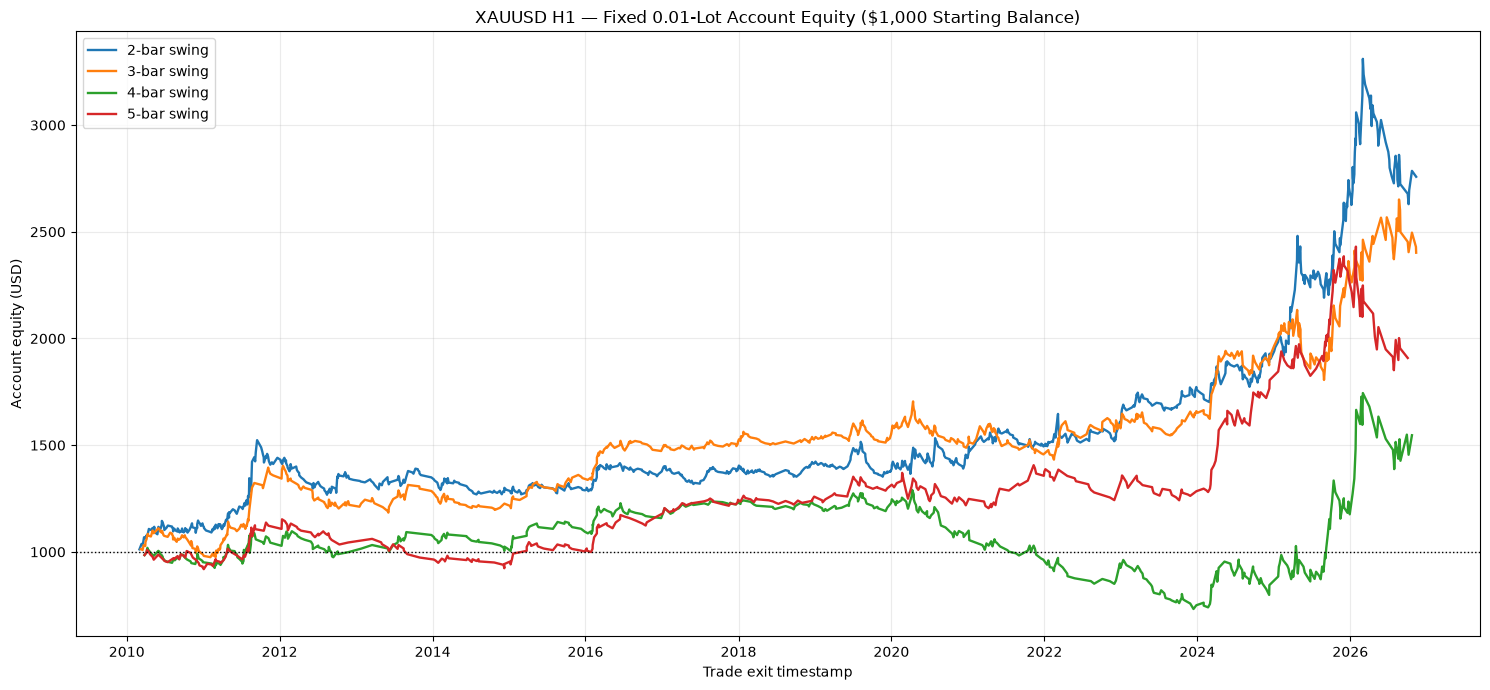

Exported account simulation summary, trade-level P/L, equity curves, and chart.


In [20]:
# Edit these assumptions to match your broker/account.
STARTING_BALANCE_USD = 1_000.0
FIXED_LOT_SIZE = 0.01
XAUUSD_CONTRACT_OZ_PER_LOT = 100.0  # common XAUUSD convention; verify with broker

USD_PER_1_PRICE_MOVE = FIXED_LOT_SIZE * XAUUSD_CONTRACT_OZ_PER_LOT

simulation_rows = []
simulation_trade_frames = []
equity_curve_frames = []


def max_consecutive_losses(pnl_series: pd.Series) -> int:
    """Count consecutive negative trade outcomes in the supplied chronological order."""
    longest = current = 0
    for is_loss in (pnl_series.to_numpy(dtype=float) < 0):
        if is_loss:
            current += 1
            longest = max(longest, current)
        else:
            current = 0
    return int(longest)


def account_stats(trades: pd.DataFrame) -> dict:
    if trades.empty:
        return {
            "Trades": 0, "Net P/L USD": 0.0,
            "Ending equity USD": STARTING_BALANCE_USD,
            "Max consecutive losses": 0, "Max drawdown USD": 0.0,
            "Worst single-trade loss USD": 0.0,
        }
    ordered = trades.sort_values(
        ["exit_date", "entry_date", "setup", "signal_date"]
    ).copy()
    event_pnl = ordered.groupby("exit_date")["P/L USD"].sum().sort_index()
    equity = STARTING_BALANCE_USD + event_pnl.cumsum()
    running_peak = equity.cummax().clip(lower=STARTING_BALANCE_USD)
    drawdown = equity - running_peak
    return {
        "Trades": len(ordered),
        "Net P/L USD": ordered["P/L USD"].sum(),
        "Ending equity USD": equity.iloc[-1],
        "Max consecutive losses": max_consecutive_losses(ordered["P/L USD"]),
        "Max drawdown USD": drawdown.min(),
        "Worst single-trade loss USD": min(0.0, ordered["P/L USD"].min()),
    }


for swing_bars in SWING_WIDTHS:
    trades = selected_frames_by_width[swing_bars].copy()
    if trades.empty:
        continue
    trades = trades[trades["result"].isin(VALID_RESULTS)].copy()
    direction = np.where(trades["side"].eq("long"), 1.0, -1.0)
    trades["Lot size"] = FIXED_LOT_SIZE
    trades["Contract size (oz/lot)"] = XAUUSD_CONTRACT_OZ_PER_LOT
    trades["P/L USD"] = (
        (trades["exit"].astype(float) - trades["entry"].astype(float))
        * direction * USD_PER_1_PRICE_MOVE
    )
    trades["Swing bars each side"] = swing_bars
    simulation_trade_frames.append(trades)

    for strategy_name, subset in [
        ("Combined — Bullish N + Ranging N", trades),
        ("Bullish N", trades[trades["setup"].eq("bullish")]),
        ("Ranging N", trades[trades["setup"].eq("ranging")]),
    ]:
        stats = account_stats(subset)
        simulation_rows.append({
            "Swing bars each side": swing_bars,
            "Selection": strategy_name,
            "Starting balance USD": STARTING_BALANCE_USD,
            "Lot size per position": FIXED_LOT_SIZE,
            **stats,
        })

    # Combined account equity curve: simultaneous exits are netted at each timestamp.
    event_pnl = trades.groupby("exit_date")["P/L USD"].sum().sort_index()
    curve = STARTING_BALANCE_USD + event_pnl.cumsum()
    curve_df = curve.rename("Equity USD").rename_axis("Timestamp").reset_index()
    curve_df["Swing bars each side"] = swing_bars
    equity_curve_frames.append(curve_df)

account_simulation_summary = pd.DataFrame(simulation_rows)
simulation_trades = (
    pd.concat(simulation_trade_frames, ignore_index=True)
    if simulation_trade_frames else pd.DataFrame()
)
account_equity_curves = (
    pd.concat(equity_curve_frames, ignore_index=True)
    if equity_curve_frames else pd.DataFrame()
)

print(
    f"Assumptions: starting balance=${STARTING_BALANCE_USD:,.2f}; "
    f"lot={FIXED_LOT_SIZE:.2f}; contract={XAUUSD_CONTRACT_OZ_PER_LOT:.0f} oz/lot; "
    f"P/L multiplier=${USD_PER_1_PRICE_MOVE:.2f} per $1.00 XAUUSD move."
)
print("Combined account simulation by swing width")
display(
    account_simulation_summary[
        account_simulation_summary["Selection"].eq("Combined — Bullish N + Ranging N")
    ][[
        "Swing bars each side", "Trades", "Net P/L USD", "Ending equity USD",
        "Max consecutive losses", "Max drawdown USD", "Worst single-trade loss USD"
    ]].round(2)
)
print("Strategy-level account simulation")
display(account_simulation_summary.round(2))

# Plot account equity curves, not normalized R curves.
plt.figure(figsize=(15, 7))
for swing_bars in SWING_WIDTHS:
    curve = account_equity_curves[
        account_equity_curves["Swing bars each side"].eq(swing_bars)
    ]
    if not curve.empty:
        plt.plot(curve["Timestamp"], curve["Equity USD"], label=f"{swing_bars}-bar swing", linewidth=1.7)
plt.axhline(STARTING_BALANCE_USD, color="black", linestyle=":", linewidth=1)
plt.title("XAUUSD H1 — Fixed 0.01-Lot Account Equity ($1,000 Starting Balance)")
plt.xlabel("Trade exit timestamp")
plt.ylabel("Account equity (USD)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
account_equity_chart = ASSET_DIR / "h1_swing_width_fixed_lot_account_equity.png"
plt.savefig(account_equity_chart, dpi=160, bbox_inches="tight")
plt.show()

# Export reproducible account-simulation outputs.
account_simulation_summary.to_csv(
    OUTPUT_DIR / "XAUUSD_H1_fixed_lot_account_simulation_summary.csv", index=False
)
if not simulation_trades.empty:
    simulation_trades.to_csv(
        OUTPUT_DIR / "XAUUSD_H1_fixed_lot_account_simulation_trades.csv", index=False
    )
if not account_equity_curves.empty:
    account_equity_curves.to_csv(
        OUTPUT_DIR / "XAUUSD_H1_fixed_lot_account_equity_curves.csv", index=False
    )
print("Exported account simulation summary, trade-level P/L, equity curves, and chart.")


## 11. Export reproducible outputs

The notebook exports candidate counts, strategy-level and combined performance, trade records, per-width capacity audits, concurrency time series, and cumulative Net R curves.

In [21]:
setup_counts.to_csv(OUTPUT_DIR / "XAUUSD_H1_swing_width_position_capped_setup_counts.csv", index=False)
performance_summary.to_csv(OUTPUT_DIR / "XAUUSD_H1_swing_width_position_capped_performance.csv", index=False)
capacity_audit.to_csv(OUTPUT_DIR / "XAUUSD_H1_swing_width_position_capped_capacity_audit.csv", index=False)
if not all_selected_trades.empty:
    all_selected_trades.to_csv(OUTPUT_DIR / "XAUUSD_H1_swing_width_position_capped_trades.csv", index=False)
if not cumulative_curves.empty:
    cumulative_curves.to_csv(OUTPUT_DIR / "XAUUSD_H1_swing_width_position_capped_cumulative_R.csv", index=False)

concurrency_all = pd.concat(concurrency_frames, ignore_index=True)
concurrency_all.to_csv(OUTPUT_DIR / "XAUUSD_H1_swing_width_position_capped_concurrency_timeseries.csv", index=False)

print("Exported files:")
for filename in [
    "XAUUSD_H1_swing_width_position_capped_setup_counts.csv",
    "XAUUSD_H1_swing_width_position_capped_performance.csv",
    "XAUUSD_H1_swing_width_position_capped_capacity_audit.csv",
    "XAUUSD_H1_swing_width_position_capped_trades.csv",
    "XAUUSD_H1_swing_width_position_capped_cumulative_R.csv",
    "XAUUSD_H1_swing_width_position_capped_concurrency_timeseries.csv",
]:
    path = OUTPUT_DIR / filename
    print(f" - {path.name}: {'created' if path.exists() else 'not created (empty result)'}")

print("\nFinal combined performance:")
display(combined_summary[[
    "Swing bars each side", "Trades", "Win rate %", "Net R",
    "Profit factor", "Avg R", "Max drawdown R", "Ambiguous OCO"
]].round(3))

Exported files:
 - XAUUSD_H1_swing_width_position_capped_setup_counts.csv: created
 - XAUUSD_H1_swing_width_position_capped_performance.csv: created
 - XAUUSD_H1_swing_width_position_capped_capacity_audit.csv: created
 - XAUUSD_H1_swing_width_position_capped_trades.csv: created
 - XAUUSD_H1_swing_width_position_capped_cumulative_R.csv: created
 - XAUUSD_H1_swing_width_position_capped_concurrency_timeseries.csv: created

Final combined performance:


,Swing bars each side,Trades,Win rate %,Net R,Profit factor,Avg R,Max drawdown R,Ambiguous OCO
0,2,1088,37.408,127.346,1.185,0.117,-33.015,9
1,3,758,37.335,88.780,1.185,0.117,-25.431,3
2,4,544,34.191,13.079,1.036,0.024,-35.455,3
3,5,426,38.498,64.976,1.247,0.153,-19.000,3


## 12. Interpretation and limitations

1. **One position per strategy, tested separately for each width.** Each swing-width experiment has its own Bullish N stream and Ranging N stream. Each stream permits at most one open position. One Bullish N and one Ranging N trade may overlap, so total active positions cannot exceed two.
2. **Regime filtering before position allocation.** Only Bullish N setups confirmed in a Bullish EMA/ADX regime and Ranging N setups confirmed in a Sideways EMA/ADX regime enter the backtest. Bearish N is excluded.
3. **Bullish N definition tightened.** This notebook explicitly requires `P1 < P3 < P2`. Its 3-bar result is therefore not guaranteed to match earlier outputs that did not explicitly enforce `P3 < P2`.
4. **Only swing width varies across the four scenarios.** EMA/ADX parameters, ATR, entry/stop buffers, range tolerance, 2R target, and pending-order expiry are fixed.
5. **Confirmation delay changes with width.** A 2-bar swing is confirmed after two bars; a 5-bar swing after five. This changes both structure sensitivity and signal timing.
6. **Full-sample model-selection bias.** All four widths are evaluated on the same historical dataset. Selecting the best width after seeing the results overfits the selection process. Freeze a candidate and test on a new unseen period or use walk-forward validation.
7. **Ranging N is an operational interpretation.** It uses two similar highs and lows within 0.50 ATR and OCO breakout orders; it is not verified as an exact proprietary N-Method rulebook.
8. **Aggregate R is not account equity.** The combined curve sums two independent streams in normalized R. It does not model lot sizing, shared capital, margin, leverage, or an account-level risk cap when both positions are open.
9. **Costs are excluded.** Spread, commission, swap, and slippage are not included and may materially affect H1 results.
10. **OHLC execution uncertainty.** Stop-loss is assumed first if SL and TP are both touched in one candle. A same-candle trigger of both OCO sides is marked ambiguous and excluded.
11. **Open positions at the sample end.** `OPEN_AT_END` is marked to the last candle close and is not a realized closed trade.
12. **Data provenance.** The input vendor and timestamp timezone were not specified in the supplied CSV. Verify redistribution rights before publishing raw data in a public repository.

### Research question

**Which swing confirmation width provides the most robust EMA/ADX-filtered N-Method performance when the one-position-per-strategy policy is enforced, and does that performance persist on unseen H1 data after realistic execution costs?**

The next step is not to keep optimizing the same full sample. Choose and freeze a candidate width, then evaluate it on unseen chronological data or through repeated walk-forward tests.
13. **Fixed-lot account simulation is illustrative.** The USD conversion assumes 100 oz per 1.00 lot and 0.01 lot = 1 oz. Verify the broker's contract size and tick value. Account equity is not margin-aware and does not model stop-out, financing, spread, commission, swap, or slippage. Consecutive-loss ordering uses exit timestamp, then entry timestamp and strategy; simultaneous exit events are netted for the equity curve.
14. **Fixed lot is not fixed risk.** Dollar risk varies with the entry-to-stop distance. A $1,000 starting balance does not guarantee the account can withstand every historical drawdown or simultaneous floating losses.
